## Visualização e pré-processamento

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Etapas deste notebook:

1. Aplicar os filtros temporais (mesmas funções do notebook `SSVEP/preprocessing.ipynb`) em cada ensaio **inteiro**, antes de recortar, para evitar efeito de borda nas janelas;
2. Visualizar o sinal nos domínios do tempo e da frequência;
3. Segmentar cada ensaio em **janelas de 4 segundos** (resolução espectral de 0,25 Hz, suficiente para separar 6 Hz de 6,5 Hz);
4. Criar o objeto `mne.EpochsArray` e salvar em `.fif`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
from scipy import signal
import mne

mne.set_log_level('WARNING')
rcParams['figure.figsize'] = [14., 4.]

fs = 512
FREQS = [6.0, 6.5, 7.0, 7.5, 8.2, 9.3, 10.0]


# definições de filtros

def passa_faixa(sinal, corte_inf, corte_sup, fs=512, ordem=4):
    nyq = fs * 0.5
    inf = corte_inf / nyq
    sup = corte_sup / nyq
    b, a = signal.butter(ordem, [inf, sup], btype='bandpass')
    return signal.filtfilt(b, a, sinal)


def rejeita_faixa(sinal, corte, meia_banda=1, fs=512, ordem=4):
    nyq = fs * 0.5
    inf = (corte - meia_banda) / nyq
    sup = (corte + meia_banda) / nyq
    b, a = signal.iirfilter(ordem, [inf, sup], btype='bandstop', ftype='butter')
    return signal.filtfilt(b, a, sinal)

In [2]:
X = np.load('dados/single_x.npy')
y = np.load('dados/single_y.npy')
print(X.shape, y.shape)

(92, 15360) (92,)


### Filtragem

- Filtro rejeita-faixa em 50 Hz (rede elétrica europeia; o equipamento já aplicou um rejeita-faixa analógico, mas o digital remove o resíduo);
- **Passa-faixa de 1 a 40 Hz**. Diferente do `preprocessing.ipynb` (4–12 Hz), aqui a faixa é mais larga porque, além do SSVEP (6–10 Hz e harmônicos até 20 Hz), preciso dos **ritmos teta, alfa e beta (até 30 Hz)** para as características de atenção.

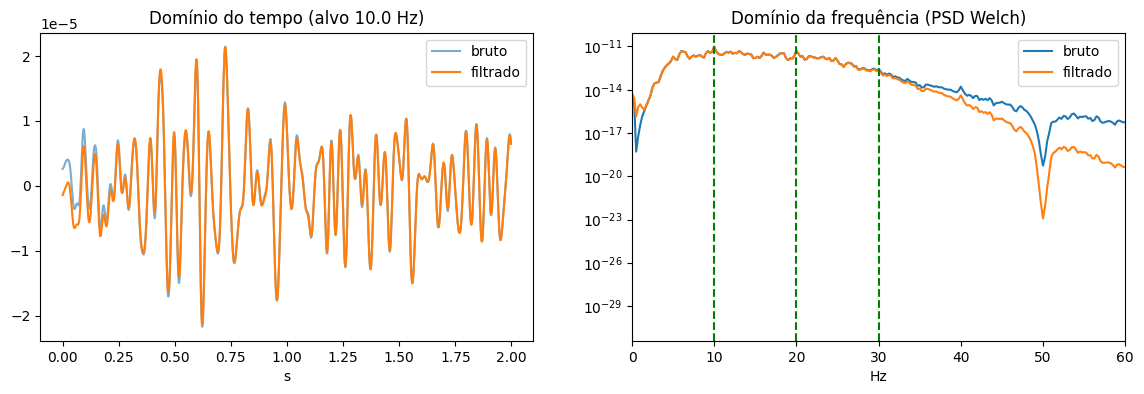

In [3]:
def filtra(x):
    x = rejeita_faixa(x, 50, fs=fs)
    return passa_faixa(x, 1., 40., fs=fs)


X_f = np.array([filtra(x) for x in X])

# comparação de um ensaio antes/depois da filtragem
i = 0
t = np.arange(X.shape[1]) / fs
fig, eixo = plt.subplots(1, 2)
eixo[0].plot(t[:2 * fs], X[i, :2 * fs], label='bruto', alpha=.6)
eixo[0].plot(t[:2 * fs], X_f[i, :2 * fs], label='filtrado')
eixo[0].set_title(f'Domínio do tempo (alvo {y[i]} Hz)'); eixo[0].set_xlabel('s'); eixo[0].legend()
for sinal, nome in ((X[i], 'bruto'), (X_f[i], 'filtrado')):
    f, P = signal.welch(sinal, fs=fs, nperseg=4 * fs)
    eixo[1].semilogy(f, P, label=nome)
for h in (1, 2, 3):
    eixo[1].axvline(y[i] * h, ls='--', c='green')
eixo[1].set_xlim(0, 60); eixo[1].set_title('Domínio da frequência (PSD Welch)'); eixo[1].set_xlabel('Hz'); eixo[1].legend()
plt.show()

Na PSD aparecem picos exatamente na frequência estimulada e nos seus harmônicos (linhas verdes): é a resposta SSVEP.

### Segmentação em janelas

Cada ensaio é recortado em janelas de 4 s sem sobreposição: os de 30 s geram 7 janelas e os de 16 s geram 4. Junto com cada janela guardo o **ensaio de origem** (`ensaio`), o **participante** e a **posição temporal** da janela no ensaio.

In [4]:
def segmenta(X_f, y, suj, janela=4.0):
    n = int(janela * fs)
    ep, rot, ensaio, part, pos = [], [], [], [], []
    for k, (x, alvo, s) in enumerate(zip(X_f, y, suj)):
        for j in range(len(x) // n):
            ep.append(x[j * n:(j + 1) * n])
            rot.append(alvo); ensaio.append(k); part.append(s); pos.append(j)
    return np.array(ep), np.array(rot), np.array(ensaio), np.array(part), np.array(pos)


def para_mne(ep, rot):
    info = mne.create_info(['Oz'], sfreq=fs, ch_types=['eeg'])
    ids_eventos = {str(f): i for i, f in enumerate(FREQS)}
    codigos = np.array([ids_eventos[str(r)] for r in rot])
    eventos = np.column_stack((np.arange(len(rot)), np.zeros(len(rot), dtype=int), codigos))
    usados = {k: v for k, v in ids_eventos.items() if v in set(codigos)}
    return mne.EpochsArray(ep[:, None, :], info, eventos, event_id=usados)


for nome in ('single', 'multi'):
    X = np.load(f'dados/{nome}_x.npy')
    y = np.load(f'dados/{nome}_y.npy')
    suj = np.load(f'dados/{nome}_sub.npy')
    X_f = np.array([filtra(x) for x in X])

    ep, rot, ensaio, part, pos = segmenta(X_f, y, suj)
    epocas = para_mne(ep, rot)
    epocas.save(f'dados/{nome}-epo.fif', overwrite=True)
    np.save(f'dados/{nome}_epocas_meta.npy', np.column_stack((rot, ensaio, part, pos)))
    print(nome, '->', epocas.get_data().shape, '(janelas, canais, amostras)')

single -> (644, 1, 2048) (janelas, canais, amostras)
multi -> (400, 1, 2048) (janelas, canais, amostras)


### PSD média por frequência estimulada

Para conferir se o SSVEP está presente em todas as classes, calculo a PSD média (método `multitaper` do MNE, como no repositório) das janelas de cada classe.

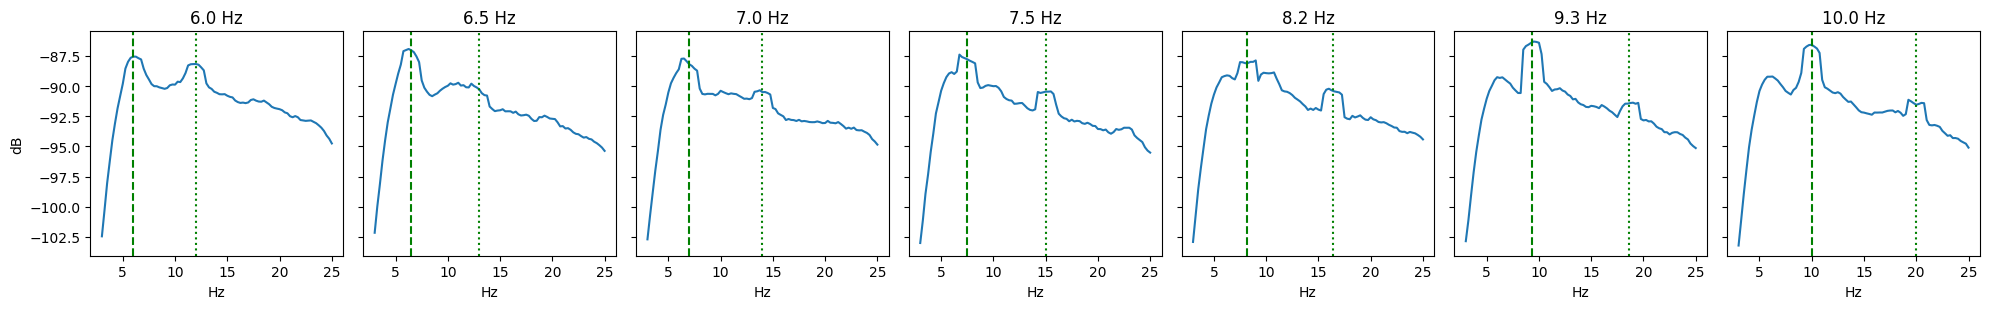

In [5]:
epocas = mne.read_epochs('dados/single-epo.fif')
fig, eixos = plt.subplots(1, 7, figsize=(20, 3.2), sharey=True)
for eixo, f0 in zip(eixos, FREQS):
    psd = epocas[str(f0)].compute_psd(method='multitaper', fmin=3, fmax=25)
    P = psd.get_data().mean(axis=(0, 1))
    eixo.plot(psd.freqs, 10 * np.log10(P))
    eixo.axvline(f0, ls='--', c='green'); eixo.axvline(2 * f0, ls=':', c='green')
    eixo.set_title(f'{f0} Hz'); eixo.set_xlabel('Hz')
eixos[0].set_ylabel('dB')
plt.tight_layout(); plt.show()

O pico da frequência fundamental aparece em todas as classes, e em várias delas (por exemplo, 6, 8,2 e 9,3 Hz) também surge um pico no **segundo harmônico** (linha pontilhada). Isso justifica usar harmônicos como característica.